In [ ]:
import os
REPO = "India-Demand-Forecasting-ML"
if not os.path.exists(REPO):
    !git clone https://github.com/tanishmaity03/India-Demand-Forecasting-ML.git
%cd {REPO}

import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
Path("results/figures").mkdir(parents=True, exist_ok=True)
Path("results/tables").mkdir(parents=True, exist_ok=True)

Cloning into 'India-Demand-Forecasting-ML'...
remote: Enumerating objects: 32, done.
remote: Counting objects: 100% (32/32), done.
remote: Compressing objects: 100% (24/24), done.
remote: Total 32 (delta 3), reused 28 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (32/32), 12.34 MiB | 17.17 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/India-Demand-Forecasting-ML


In [ ]:
india = pd.read_excel("data/raw/hourlyLoadDataIndia.xlsx")
india.columns = ["datetime", "national", "northern", "western", "eastern", "southern", "north_eastern"]
india["datetime"] = pd.to_datetime(india["datetime"])
india = india.sort_values("datetime").reset_index(drop=True)
REGIONS = ["northern", "western", "eastern", "southern", "north_eastern"]
print(india.shape)
india.head()

(46728, 7)


,datetime,national,northern,western,eastern,southern,north_eastern
0,2019-01-01 00:00:00,118690.67,33692.02,38522.22,13128.89,31681.83,1665.72
1,2019-01-01 01:00:00,116029.23,32534.39,38071.09,12737.53,31129.97,1556.24
2,2019-01-01 02:00:00,114044.14,31730.37,37680.10,12387.36,30760.87,1485.44
3,2019-01-01 03:00:00,113648.97,31529.25,37747.37,12301.12,30616.27,1454.96
4,2019-01-01 04:00:00,116290.05,32406.61,38101.80,12479.13,31839.38,1463.14


In [ ]:
def audit_hourly(df, ts_col, value_cols, name, source, role):
    full = pd.date_range(df[ts_col].min(), df[ts_col].max(), freq="h")
    return pd.Series({
        "dataset": name, "source": source, "role": role,
        "rows": len(df), "start": df[ts_col].min(), "end": df[ts_col].max(),
        "expected_hours": len(full),
        "missing_timestamps": len(full.difference(df[ts_col])),
        "duplicate_timestamps": int(df[ts_col].duplicated().sum()),
        "missing_values": int(df[value_cols].isna().sum().sum()),
        "non_positive_values": int((df[value_cols] <= 0).sum().sum()),
    })

audit_india = audit_hourly(india, "datetime", ["national"] + REGIONS,
                           "India hourly demand", "hourlyLoadDataIndia (confirm source)", "Main dataset")
print(audit_india)

gap = (india[REGIONS].sum(axis=1) - india["national"]).abs().max()
print("\nMax |sum(regions) - national| (MW):", round(gap, 4))

dataset                                  India hourly demand
source                  hourlyLoadDataIndia (confirm source)
role                                            Main dataset
rows                                                   46728
start                                    2019-01-01 00:00:00
end                                      2024-04-30 23:00:00
expected_hours                                         46728
missing_timestamps                                         0
duplicate_timestamps                                       0
missing_values                                             0
non_positive_values                                        0
dtype: object

Max |sum(regions) - national| (MW): 0.02


In [ ]:
stats = india.drop(columns="datetime").describe().T.round(1)
stats.to_csv("results/tables/india_demand_summary_stats.csv")
stats

,count,mean,std,min,25%,50%,75%,max
national,46728.0,160487.1,23103.6,95336.6,145338.8,159541.1,176633.6,237362.0
northern,46728.0,47914.8,10502.9,19217.8,40165.9,47523.7,55012.2,80793.9
western,46728.0,50402.9,7995.6,28111.2,44272.4,50037.0,56100.5,73015.2
eastern,46728.0,18572.5,3329.7,9259.8,16107.2,18427.6,20828.4,28856.6
southern,46728.0,41589.5,7467.0,23188.9,36156.9,40681.9,46101.8,68207.9
north_eastern,46728.0,2007.4,436.6,567.0,1689.2,1968.6,2290.2,3586.4


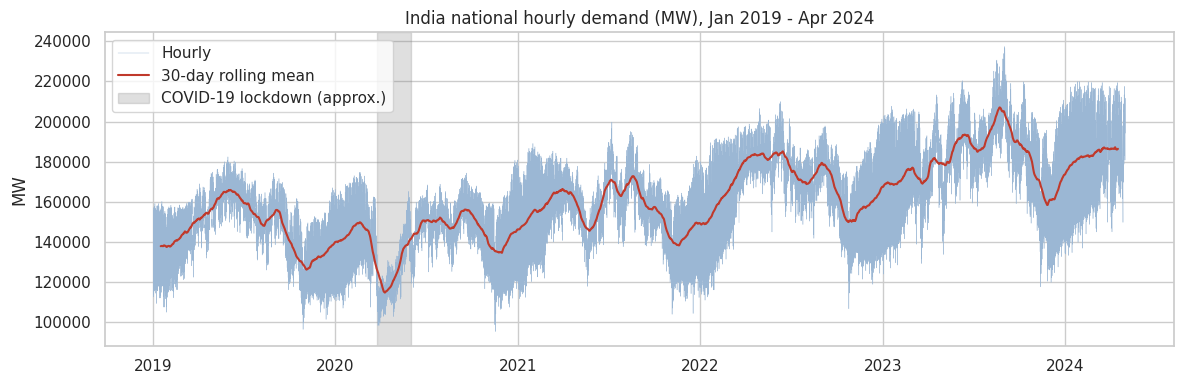

In [ ]:
s = india.set_index("datetime")["national"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(s.index, s.values, lw=0.3, color="#9bb7d4", label="Hourly")
ax.plot(s.index, s.rolling(24 * 30, center=True).mean(), lw=1.5, color="#c0392b", label="30-day rolling mean")
ax.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-05-31"), color="grey", alpha=0.25,
           label="COVID-19 lockdown (approx.)")
ax.set_title("India national hourly demand (MW), Jan 2019 - Apr 2024")
ax.set_ylabel("MW"); ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("results/figures/01_india_national_demand.png", dpi=150)
plt.show()

In [ ]:
df.describe().T.round(3)

,count,mean,min,25%,50%,75%,max,std
timestamp,50000,2024-09-17 09:52:30.000000256,2024-01-01 00:00:00,2024-05-10 04:56:15,2024-09-17 09:52:30,2025-01-25 14:48:45,2025-06-04 19:45:00,NaN
voltage_v,50000.0,229.997896,207.671981,226.606874,230.008697,233.385302,252.395421,5.000849
current_a,50000.0,27.482627,5.001239,16.144764,27.580058,38.778588,49.999642,12.984307
power_kw,50000.0,6.320811,1.089178,3.706998,6.340475,8.914134,12.103199,2.990096
reactive_kvar,50000.0,1.584137,0.113665,0.805235,1.386541,2.209433,4.684119,0.964876
power_factor,50000.0,0.899997,0.800001,0.84993,0.900119,0.949748,0.999997,0.05774
solar_kw,50000.0,25.075357,0.000115,12.597064,25.031922,37.527215,49.998963,14.434644
wind_kw,50000.0,15.008312,0.000067,7.495573,15.035654,22.528948,29.997815,8.66307
grid_supply_kw,50000.0,0.047198,0.0,0.0,0.0,0.0,10.766046,0.460281
voltage_fluct_pct,50000.0,-0.002723,-4.999913,-2.506506,-0.009397,2.493917,4.999946,2.884219


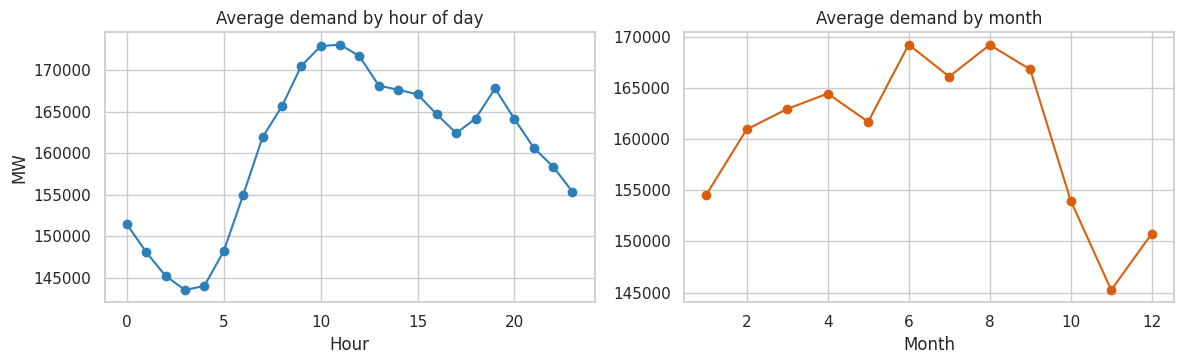

Autocorrelation  lag 1h: 0.979 | lag 24h: 0.969 | lag 168h: 0.921


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
s.groupby(s.index.hour).mean().plot(ax=axes[0], marker="o", color="#2c7fb8")
axes[0].set_title("Average demand by hour of day"); axes[0].set_xlabel("Hour"); axes[0].set_ylabel("MW")
s.groupby(s.index.month).mean().plot(ax=axes[1], marker="o", color="#d95f0e")
axes[1].set_title("Average demand by month"); axes[1].set_xlabel("Month")
plt.tight_layout()
plt.savefig("results/figures/01_india_hourly_monthly_profile.png", dpi=150)
plt.show()

print("Autocorrelation  lag 1h: %.3f | lag 24h: %.3f | lag 168h: %.3f"
      % (s.autocorr(1), s.autocorr(24), s.autocorr(168)))

In [ ]:
load = pd.read_csv("data/raw/load_dataset.csv")
load.columns = [c.strip().lower().replace(" ", "_") for c in load.columns]
load["datetime"] = pd.to_datetime(dict(year=load["year"], month=load["mo"], day=load["dy"], hour=load["hr"]))

audit_load = audit_hourly(load, "datetime", ["electric_load"], "load_dataset (weather + load)",
                          "NASA-POWER-style weather columns (confirm source/location)", "Weather-impact case study")
print(audit_load)
print("\nIrradiance sentinel values (-999):", int((load["irradiance"] == -999).sum()))
print("Load <= 0 rows:", int((load["electric_load"] <= 0).sum()))
print("Corr(temperature, load): %.2f" % load[["temperature", "electric_load"]].corr().iloc[0, 1])

dataset                                     load_dataset (weather + load)
source                  NASA-POWER-style weather columns (confirm sour...
role                                            Weather-impact case study
rows                                                                 8779
start                                                 2021-11-01 05:00:00
end                                                   2022-11-01 23:00:00
expected_hours                                                       8779
missing_timestamps                                                      0
duplicate_timestamps                                                    0
missing_values                                                          0
non_positive_values                                                    79
dtype: object

Irradiance sentinel values (-999): 24
Load <= 0 rows: 79
Corr(temperature, load): 0.61


In [ ]:
pan = pd.read_csv("data/external/continuous_dataset.csv", parse_dates=["datetime"])
audit_pan = audit_hourly(pan, "datetime", ["nat_demand"], "Panama continuous dataset",
                         "Panama national demand + 3-city weather (NOT India)", "External benchmark only")
print(audit_pan)
pan[["datetime", "nat_demand", "T2M_toc", "holiday", "school"]].head(3)

dataset                                         Panama continuous dataset
source                  Panama national demand + 3-city weather (NOT I...
role                                              External benchmark only
rows                                                                48048
start                                                 2015-01-03 01:00:00
end                                                   2020-06-27 00:00:00
expected_hours                                                      48048
missing_timestamps                                                      0
duplicate_timestamps                                                    0
missing_values                                                          0
non_positive_values                                                     0
dtype: object


,datetime,nat_demand,T2M_toc,holiday,school
0,2015-01-03 01:00:00,970.3450,25.865259,0,0
1,2015-01-03 02:00:00,912.1755,25.899255,0,0
2,2015-01-03 03:00:00,900.2688,25.937280,0,0


In [ ]:
inventory = pd.DataFrame([audit_india, audit_load, audit_pan])
inventory.to_csv("results/tables/dataset_inventory.csv", index=False)
inventory.T

,0,1,2
dataset,India hourly demand,load_dataset (weather + load),Panama continuous dataset
source,hourlyLoadDataIndia (confirm source),NASA-POWER-style weather columns (confirm sour...,Panama national demand + 3-city weather (NOT I...
role,Main dataset,Weather-impact case study,External benchmark only
rows,46728,8779,48048
start,2019-01-01 00:00:00,2021-11-01 05:00:00,2015-01-03 01:00:00
end,2024-04-30 23:00:00,2022-11-01 23:00:00,2020-06-27 00:00:00
expected_hours,46728,8779,48048
missing_timestamps,0,0,0
duplicate_timestamps,0,0,0
missing_values,0,0,0
